In [59]:
import numpy as np 
import pandas as pd
import torch
import matplotlib.pyplot as plt
from numpy.linalg import svd
from PIL import Image
import ipytest
ipytest.autoconfig()
import random

In [15]:
# Load numerical data, skipping the first header row
v = np.loadtxt('v.csv', delimiter=',', skiprows=0)
s_diag = np.loadtxt('s.csv', delimiter=',', skiprows=0)
u = np.loadtxt('u.csv', delimiter=',', skiprows=0)
s = np.diag(s_diag)

B. Convert to tensors

In [16]:
v_tensor = torch.from_numpy(v)
s_tensor = torch.from_numpy(s)
u_tensor = torch.from_numpy(u)

C. reconstruct

Reconstruct the full matrix by multiplying the 3 pytorch tensors, using the pytorch matrix multiplication method (NOT element-wise multiplication) from the tutorial. 

This is the uncompressed image. Use the plotting code from the eagles project to turn the matrix into a plot. If you do it right, you should see a lovely image of Ada Lovelace, the inventor of computer programming. If you get a grey box, you probably didn't multiply the matrices in the correct order. 

In [52]:
img = torch.mm(u_tensor,s_tensor)
img = torch.mm(img,v_tensor)

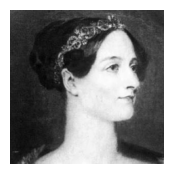

In [ ]:
plt.subplots(figsize=(2, 2))
plt.axis('off')
plt.imshow(img, cmap=plt.cm.gray )

Part 3

Reconstruct a compressed image by reducing the rank of the  matrix. You want to still be able to make out the image, so don't reduce it too much. I don't have a preconceived notion for how much to reduce it by; just play around until you are happy. Use the slicing methods described in the tutorial from part 1. You must use PYTORCH methods to get credit for this - you should not be using numpy methods because our goal is to practice pytorch.

In [144]:
def reconstruct(M, k):
    Sprime = s_tensor[0:k, 0:k]
    Uprime = u_tensor[:,0:k]
    Vprime = v_tensor[:k,:]
    return torch.mm(torch.mm(Uprime,Sprime),Vprime)

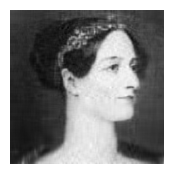

In [147]:
k = 22
A = reconstruct(img,k) 
plt.figure(figsize=(2, 2))
plt.axis('off')
plt.imshow(A, cmap=plt.cm.gray)
